# Final model comparison, test-set evaluation and report section (issue #18)

Steps: (1) summarise everything in `results/model_results.csv`; (2) decide which differences are real; (3) score the **test set once** with the top 3 models and the thresholds from #15; (4) write the report section (`reports/model_comparison_report.md`).

**Scope note.** Issue #17 (logistic regression, random forest, ExtraTrees, kNN, SVM, MLP) was not finished when this was run, so those families are *not* in the comparison. Only gradient-boosting models (#9-#13) are compared here, plus the trivial baselines. If #17 produces a model with a nested-CV AUC above the boosting results, add it to the table and re-run section 2 (the test cell will not re-score; see below).

**Rules fixed before looking at the test set**
- Model selection uses only development-data CV results (nested CV for tuned models).
- Top 3 = the three tuned models with the highest nested-CV mean ROC AUC in the log.
- Features: the 6 raw sensors (decision from #14).
- Thresholds: 0.50 (cost-optimal when a miss costs the same as an unneeded inspection, #15) and 0.65 (peak balanced accuracy, #15). Both come from out-of-fold predictions on dev data.
- The test cell writes `results/test_results.csv`; if that file exists it loads it instead of scoring again.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

from src.common import load_dev, load_test, get_cv, RANDOM_STATE, ROOT
warnings.filterwarnings('ignore')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
log = pd.read_csv(ROOT / 'results' / 'model_results.csv')
print(len(log), 'logged runs')

26 logged runs


## 1. One table and one plot from the results log

All CV rows on the 6 raw sensors, latest run per model name. Tuned rows are nested CV.

In [2]:
raw = log[log['features'] == 'raw'].drop_duplicates('model', keep='last')
raw = raw[~raw['model'].str.contains('class_weight|no class weights', regex=True) & ~raw['notes'].fillna('').str.contains('#14')]
cols = ['model', 'cv_auc_mean', 'cv_auc_std', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean', 'fit_time_mean_s']
table = raw[cols].sort_values('cv_auc_mean', ascending=False).reset_index(drop=True)
table.to_csv(ROOT / 'reports' / 'model_comparison_table.csv', index=False)
table

,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,CatBoost tuned,0.7030,0.0085,0.8004,0.7632,0.8437,0.6967,28.000
1,LightGBM tuned,0.7025,0.0088,0.7999,0.7616,0.8379,0.6980,20.600
2,GradientBoosting (sklearn) tuned,0.7020,0.0088,0.7991,0.7642,0.8513,0.6933,181.000
3,XGBoost tuned,0.7018,0.0088,0.7995,0.7645,0.8551,0.6913,9.500
4,GradientBoosting (sklearn),0.7007,0.0085,0.7977,0.7614,0.8409,0.6956,1.328
5,HistGradientBoosting (sklearn) tuned,0.7003,0.0092,0.7977,0.7616,0.8382,0.6978,7.400
6,HistGradientBoosting (sklearn),0.6957,0.0100,0.7950,0.7585,0.8367,0.6937,0.058
7,CatBoost,0.6915,0.0086,0.7928,0.7555,0.8280,0.6946,2.498
8,LightGBM,0.6896,0.0091,0.7907,0.7550,0.8258,0.6955,0.068
9,XGBoost,0.6620,0.0109,0.7699,0.7370,0.7900,0.6907,0.084


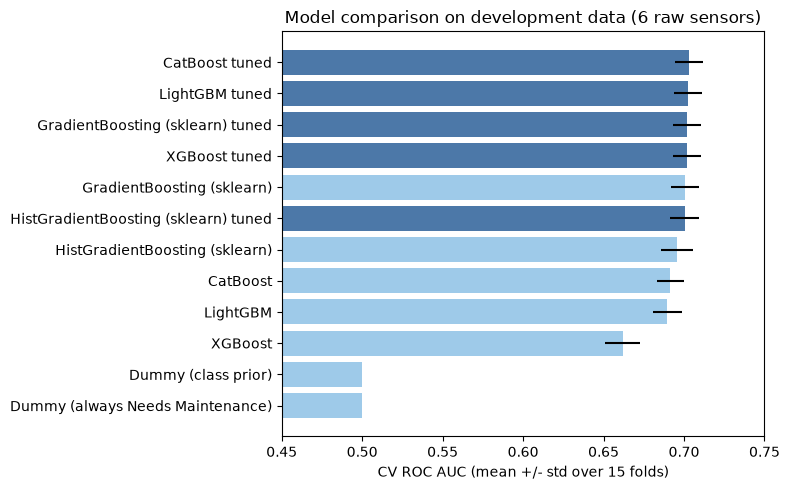

In [3]:
t = table.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(t['model'], t['cv_auc_mean'], xerr=t['cv_auc_std'], color=['#4c78a8' if ' tuned' in m else '#9ecae9' for m in t['model']])
ax.set_xlim(0.45, 0.75); ax.set_xlabel('CV ROC AUC (mean +/- std over 15 folds)')
ax.set_title('Model comparison on development data (6 raw sensors)')
plt.tight_layout(); plt.savefig(FIG / 'final_model_comparison.png', dpi=130); plt.show()

## 2. Which differences are real?

Final tuned configurations (saved in `results/best_params_*.json`) are scored on the same 15 CV folds, so the AUC of the same fold can be compared. With repeated CV the folds share data, so a plain paired t-test is too optimistic; we use the **corrected resampled t-test** (Nadeau & Bengio): variance multiplied by (1/15 + n_test/n_train) = 1/15 + 1/4.

Caveat: the final parameters were chosen on all dev data, so these fold AUCs are a little optimistic for every model alike. The absolute levels in section 1 (nested CV) are the honest ones; this section is only for the **differences**.

In [4]:
P = lambda n: json.loads((ROOT / 'results' / f'best_params_{n}.json').read_text())
sk = P('sklearn')
MODELS = {
 'CatBoost tuned':  lambda: CatBoostClassifier(**P('catboost'), random_seed=RANDOM_STATE, thread_count=1, verbose=0, allow_writing_files=False),
 'LightGBM tuned':  lambda: LGBMClassifier(**P('lightgbm'), subsample_freq=1, random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
 'XGBoost tuned':   lambda: XGBClassifier(**P('xgboost'), random_state=RANDOM_STATE, n_jobs=1, tree_method='hist'),
 'GradientBoosting (sklearn) tuned': lambda: GradientBoostingClassifier(**sk['GradientBoosting (sklearn)'], random_state=RANDOM_STATE),
 'HistGradientBoosting (sklearn) tuned': lambda: HistGradientBoostingClassifier(**sk['HistGradientBoosting (sklearn)'], early_stopping=True, random_state=RANDOM_STATE),
}
X, y = load_dev()
fold_auc = {n: cross_validate(mk(), X, y, cv=get_cv(), scoring='roc_auc', n_jobs=-1)['test_score'] for n, mk in MODELS.items()}
fa = pd.DataFrame(fold_auc)
print(fa.mean().round(4).to_string())

CatBoost tuned                          0.7036
LightGBM tuned                          0.7025
XGBoost tuned                           0.7020
GradientBoosting (sklearn) tuned        0.7016
HistGradientBoosting (sklearn) tuned    0.7004


In [5]:
best = fa.mean().idxmax()
K, ratio = len(fa), 1/4
rows = []
for m in fa.columns:
    if m == best: continue
    d = (fa[best] - fa[m]).values
    se = np.sqrt((1/K + ratio) * d.var(ddof=1))
    t_ = d.mean() / se; p = 2 * stats.t.sf(abs(t_), df=K-1)
    rows.append({'best': best, 'vs': m, 'mean AUC diff': round(d.mean(), 4), 'corrected t': round(t_, 2), 'p (two-sided)': round(p, 3)})
pairs = pd.DataFrame(rows); print('smallest p-value of', len(pairs), 'comparisons; Bonferroni threshold =', round(0.05/len(pairs), 4))
pairs

smallest p-value of 4 comparisons; Bonferroni threshold = 0.0125


,best,vs,mean AUC diff,corrected t,p (two-sided)
0,CatBoost tuned,LightGBM tuned,0.0011,1.41,0.179
1,CatBoost tuned,XGBoost tuned,0.0016,2.88,0.012
2,CatBoost tuned,GradientBoosting (sklearn) tuned,0.0020,2.29,0.038
3,CatBoost tuned,HistGradientBoosting (sklearn) tuned,0.0032,2.99,0.010


## 3. Score the test set once

Top 3 tuned models by nested-CV AUC from the log. Fit on all development data (train + val), predict the test set, and apply the two fixed thresholds. Predictions are stored so nothing needs to be re-scored.

In [6]:
tuned = log[(log['features'] == 'raw') & log['model'].str.endswith(' tuned')].drop_duplicates('model', keep='last')
top3 = tuned.sort_values('cv_auc_mean', ascending=False).head(3)['model'].tolist()
print('top 3 by nested-CV AUC:', top3)
assert all(m in MODELS for m in top3)

RES = ROOT / 'results' / 'test_results.csv'; PRED = ROOT / 'results' / 'test_predictions.csv'
THRESHOLDS = [0.50, 0.65]
if RES.exists() and PRED.exists():
    print('Test set was already scored; loading saved results (not re-scoring).')
    res, preds = pd.read_csv(RES), pd.read_csv(PRED)
    y_te = preds['y_true'].values
else:
    X_te, y_te_s = load_test(confirm=True)           # the single look at the test set
    y_te = y_te_s.values
    preds = pd.DataFrame({'y_true': y_te}); out = []
    rng = np.random.default_rng(RANDOM_STATE)
    for m in top3:
        p = MODELS[m]().fit(X, y).predict_proba(X_te)[:, 1]; preds[m] = p
        boots = [roc_auc_score(y_te[i], p[i]) for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(1000))]
        for t in THRESHOLDS:
            pr = p >= t; tp = (pr & (y_te == 1)).sum()
            out.append({'model': m, 'threshold': t, 'test_auc': roc_auc_score(y_te, p),
                        'auc_ci95_low': np.percentile(boots, 2.5), 'auc_ci95_high': np.percentile(boots, 97.5),
                        'test_pr_auc': average_precision_score(y_te, p),
                        'precision': tp / max(pr.sum(), 1), 'recall': tp / (y_te == 1).sum(),
                        'f1': 2 * tp / (pr.sum() + (y_te == 1).sum()), 'flagged_%': 100 * pr.mean()})
    res = pd.DataFrame(out); res.to_csv(RES, index=False); preds.to_csv(PRED, index=False)
print('test rows:', len(y_te), '| share Needs Maintenance:', round(y_te.mean(), 3), '(always-flag precision = that share)')
res.round(4)

top 3 by nested-CV AUC: ['CatBoost tuned', 'LightGBM tuned', 'GradientBoosting (sklearn) tuned']
Test set was already scored; loading saved results (not re-scoring).
test rows: 2931 | share Needs Maintenance: 0.631 (always-flag precision = that share)


,model,threshold,test_auc,auc_ci95_low,auc_ci95_high,test_pr_auc,precision,recall,f1,flagged_%
0,CatBoost tuned,0.50,0.7085,0.6902,0.7282,0.8054,0.6942,0.8366,0.7588,75.9809
1,CatBoost tuned,0.65,0.7085,0.6902,0.7282,0.8054,0.8016,0.5795,0.6727,45.5817
2,LightGBM tuned,0.50,0.7077,0.6901,0.7255,0.8053,0.6990,0.8393,0.7627,75.7079
3,LightGBM tuned,0.65,0.7077,0.6901,0.7255,0.8053,0.7931,0.5850,0.6733,46.5029
4,GradientBoosting (sklearn) tuned,0.50,0.7044,0.6844,0.7224,0.8015,0.6850,0.8615,0.7632,79.2903
5,GradientBoosting (sklearn) tuned,0.65,0.7044,0.6844,0.7224,0.8015,0.7922,0.5736,0.6654,45.6499


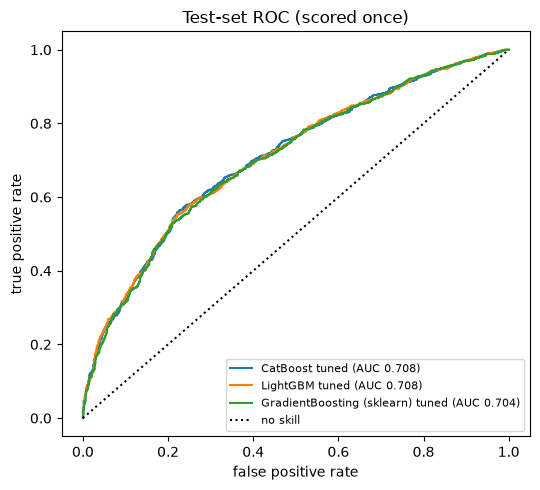

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for m in top3:
    fpr, tpr, _ = roc_curve(preds['y_true'], preds[m]); ax.plot(fpr, tpr, label=f"{m} (AUC {roc_auc_score(preds['y_true'], preds[m]):.3f})")
ax.plot([0, 1], [0, 1], 'k:', label='no skill'); ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate')
ax.set_title('Test-set ROC (scored once)'); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'final_test_roc.png', dpi=130); plt.show()